In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
## Load raw dataset
path = r"D:\Planetary Defense Analytics Project"
print(os.listdir(path))

['01.Data cleaning.ipynb', '02. Data_preprocessing.ipynb', '03.Classifcation.ipynb', '04.Update preprocessing_regression.ipynb', '05. Regression.ipynb', '06.Clustering.ipynb', '07.Model Saving .ipynb', '08.Explainable AI(SHAP).ipynb', 'app01.py', 'confusion_matrices.png', 'ML Flow.ipynb', 'mlruns', 'pha_dataset.csv', 'pha_dataset_cleaned.csv', 'processed_data', 'processed_regression', 'README.md', 'requirements.txt', 'results', 'saved_models']


In [3]:
#STEP 1: LOAD DATA & DEFINE COLUMN ROLES
df=pd.read_csv("pha_dataset.csv")

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4244\885705870.py:2: DtypeWarning: Columns (0: pdes, 1: name, 2: prefix) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("pha_dataset.csv")


Understanding the Data

In [4]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [4]:
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nData Types:")
print(df.dtypes.value_counts())

Dataset Shape: 958524 rows, 45 columns

Data Types:
float64    33
str         9
int64       2
object      1
Name: count, dtype: int64


In [6]:
#Check column names 
df.columns

Index(['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix', 'neo', 'pha', 'H',
       'diameter', 'albedo', 'diameter_sigma', 'orbit_id', 'epoch',
       'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w',
       'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld',
       'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w',
       'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'class',
       'rms'],
      dtype='str')

In [ ]:
#Basic information
df.info()

In [8]:
#Statistical summary
df.describe()

,spkid,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,e,a,...,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,rms
count,9.585240e+05,952261.000000,136209.000000,135103.000000,136081.000000,9.585240e+05,958524.000000,9.585240e+05,958524.000000,958524.000000,...,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.385980e+05,9.386020e+05,9.386020e+05,9.385980e+05,958522.000000
mean,3.810114e+06,16.906411,5.506429,0.130627,0.479184,2.458869e+06,58868.781950,2.019693e+07,0.156116,2.902143,...,1.982929e+01,1.168449e+00,5.310234e+00,1.370062e+06,1.369977e+06,2.131453e+01,5.060221e-02,4.312780e+08,8.525815e+04,0.561153
std,6.831541e+06,1.790405,9.425164,0.110323,0.782895,7.016716e+02,701.671573,1.930354e+04,0.092643,39.719503,...,2.903785e+03,1.282231e+02,1.333381e+03,9.158996e+08,9.158991e+08,7.197034e+03,9.814953e+00,2.953046e+11,2.767681e+07,2.745700
min,2.000001e+06,-1.100000,0.002500,0.001000,0.000500,2.425052e+06,25051.000000,1.927062e+07,0.000000,-14702.447872,...,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,0.000000
25%,2.239632e+06,16.100000,2.780000,0.053000,0.180000,2.459000e+06,59000.000000,2.020053e+07,0.092193,2.387835,...,1.462000e-07,6.095900e-06,3.619400e-05,5.755000e-05,2.573700e-05,2.340900e-08,2.768800e-09,1.110900e-04,1.794500e-05,0.518040
50%,2.479262e+06,16.900000,3.972000,0.079000,0.332000,2.459000e+06,59000.000000,2.020053e+07,0.145002,2.646969,...,2.271900e-07,8.688800e-06,6.642550e-05,1.047100e-04,4.900100e-05,4.359000e-08,4.638000e-09,2.230800e-04,3.501700e-05,0.566280
75%,3.752518e+06,17.714000,5.765000,0.190000,0.620000,2.459000e+06,59000.000000,2.020053e+07,0.200650,3.001932,...,6.583200e-07,1.591500e-05,1.609775e-04,3.114400e-04,1.718900e-04,1.196600e-07,1.124000e-08,8.139600e-04,9.775475e-05,0.613927
max,5.401723e+07,33.200000,939.400000,1.000000,140.000000,2.459000e+06,59000.000000,2.020053e+07,1.855356,33488.895955,...,1.015000e+06,5.533000e+04,1.199100e+06,8.845100e+11,8.845100e+11,5.509700e+06,7.698800e+03,2.853100e+14,1.910700e+10,2686.600000


In [6]:
# 1. Identifiers to drop immediately
identifiers = ["id", "spkid", "pdes", "full_name", "name"]

In [5]:
# 2. Leakage columns to drop for Case 1 (pha classification)
leakage_case1 = ["moid", "moid_ld", "neo"]

In [7]:
# 3. Genuine predictors for Case 1
predictors_case1 = [
    "a",
    "e",
    "i",
    "q",
    "ad",
    "n",
    "per",
    "H",
    "om",
    "w",
    "ma",
    "class",]
target_case1 = "pha"

In [8]:
# Keep only valid columns for modeling
cols_to_keep = predictors_case1 + [target_case1]
df_model = df[cols_to_keep].copy()

STEP 2: DATA CLEANING

In [9]:
# A. Drop Duplicate Rows
df_model = df_model.drop_duplicates()

In [10]:
# B. Drop rows with missing Target (pha)
df_model = df_model.dropna(subset=[target_case1])

In [11]:
# C. Convert Target 'pha' (Y/N) to Binary (1/0)
df_model[target_case1] = (
    df_model[target_case1].astype(str).str.upper().map({"Y": 1, "N": 0}))

In [12]:
# D. Filter Physically Impossible Orbital Parameters
# - Bound elliptical orbits: 0 <= eccentricity (e) < 1.0
# - Semi-major axis (a) and Perihelion (q) must be > 0
df_clean = df_model[
    (df_model["e"] >= 0)
    & (df_model["e"] < 1.0)
    & (df_model["a"] > 0)
    & (df_model["q"] > 0)].copy()

print("--- CLEANING COMPLETED ---")
print(f"Original Dataset Shape : {df.shape}")
print(f"Cleaned Modeling Shape : {df_clean.shape}")
print(f"Target Distribution    :\n{df_clean[target_case1].value_counts()}")

--- CLEANING COMPLETED ---
Original Dataset Shape : (958524, 45)
Cleaned Modeling Shape : (938599, 13)
Target Distribution    :
pha
0    936533
1      2066
Name: count, dtype: int64


 Exploratory Data Analysis & Visualization 


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
# Set global visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

1. UNIVARIATE ANALYSIS (NUMERICAL HISTOGRAMS & CATEGORICAL BAR PLOTS)

In [15]:
def plot_univariate_analysis(df):
    # A. Numeric Features Distributions
    num_cols = ["e", "a", "i", "H", "q", "ad"]
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(
        "Univariate Numeric Features (Raw vs Log Scales)",
        fontsize=16,
        fontweight="bold",)
    

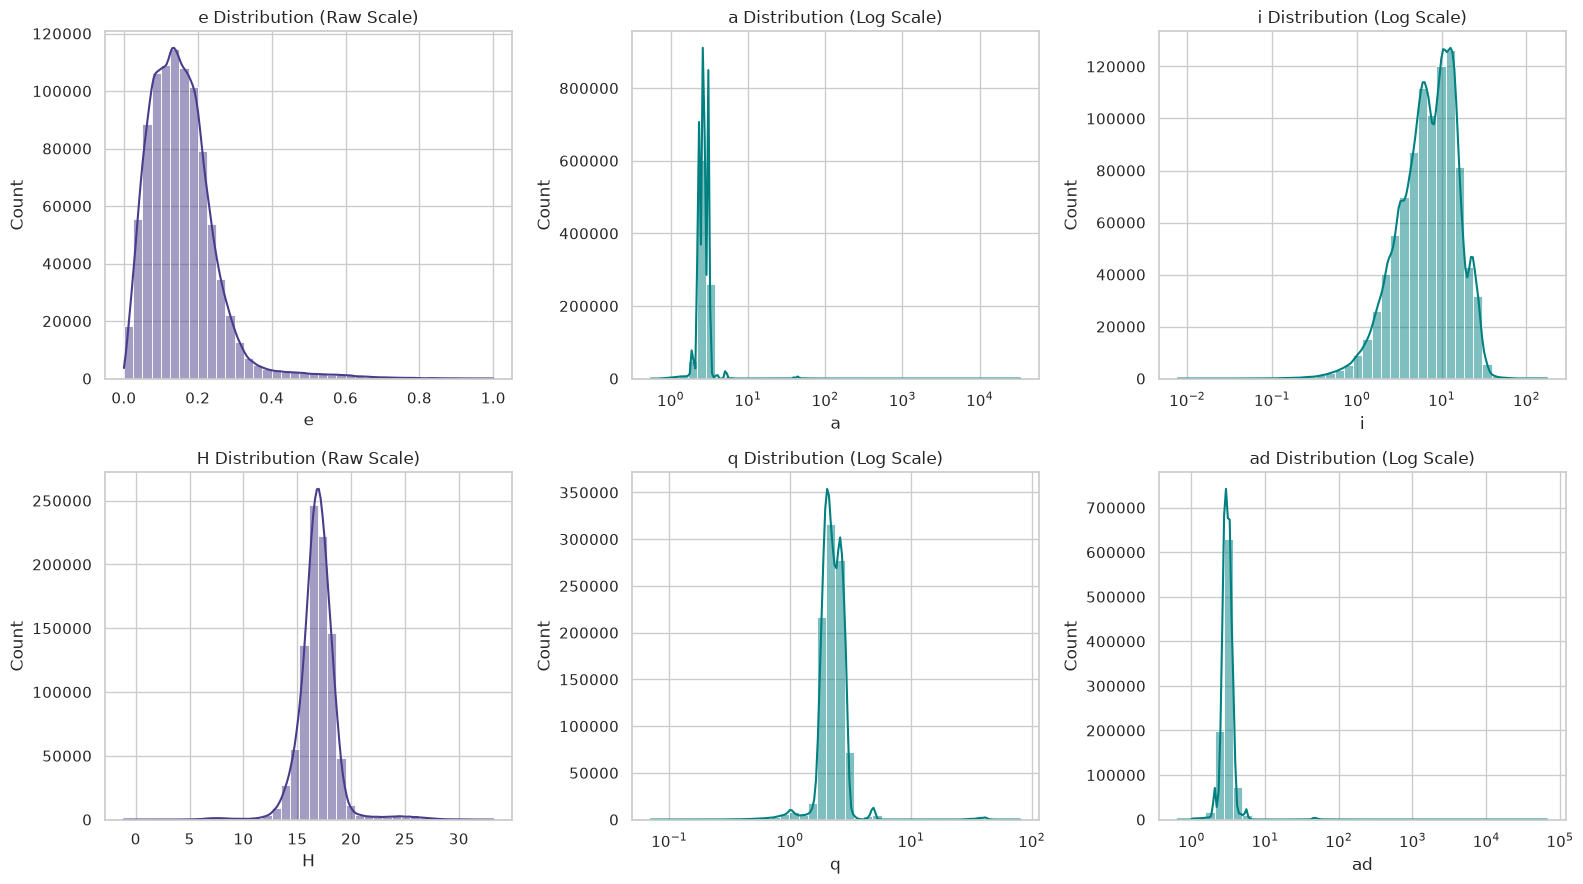

In [16]:
# Option A: Define the variables before the loop
num_cols = ["e", "a", "i", "H", "q", "ad"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for idx, col in enumerate(num_cols):
    ax = axes[idx // 3, idx % 3]
    if df_clean[col].skew() > 2.0:
        sns.histplot(
            df_clean[col], kde=True, ax=ax, log_scale=True, color="teal", bins=40        )
        ax.set_title(f"{col} Distribution (Log Scale)")
    else:
        sns.histplot(
            df_clean[col], kde=True, ax=ax, color="darkslateblue", bins=40        )
        ax.set_title(f"{col} Distribution (Raw Scale)")

plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_588\2082205302.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="pha", data=df, ax=axes[0], palette="Set2")
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_588\2082205302.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="neo", data=df, ax=axes[1], palette="Set1")
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_588\2082205302.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


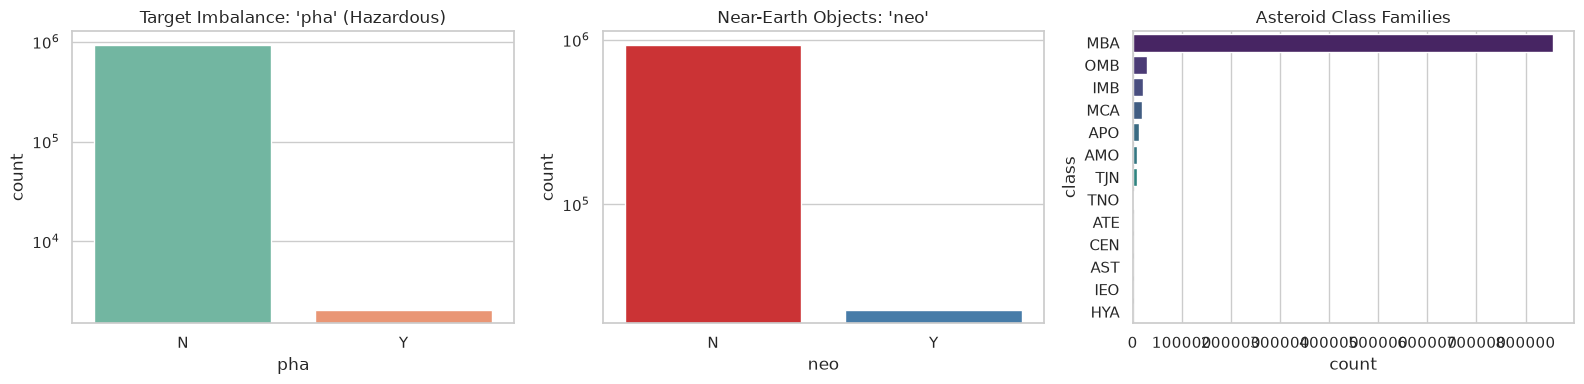

In [44]:
# B. Categorical Features & Target Imbalance
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # Target class balance
if "pha" in df.columns:
        sns.countplot(x="pha", data=df, ax=axes[0], palette="Set2")
        axes[0].set_title("Target Imbalance: 'pha' (Hazardous)")
        axes[0].set_yscale("log")  # Log scale to make rare class visible

if "neo" in df.columns:
        sns.countplot(x="neo", data=df, ax=axes[1], palette="Set1")
        axes[1].set_title("Near-Earth Objects: 'neo'")
        axes[1].set_yscale("log")

if "class" in df.columns:
        sns.countplot(
            y="class",
            data=df,
            ax=axes[2],
            order=df["class"].value_counts().index,
            palette="viridis",        )
        axes[2].set_title("Asteroid Class Families")

plt.tight_layout()
plt.show()

# 2. BIVARIATE ANALYSIS (PREDICTIVE POWER & LEAKAGE DETECTION)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4244\2998630769.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


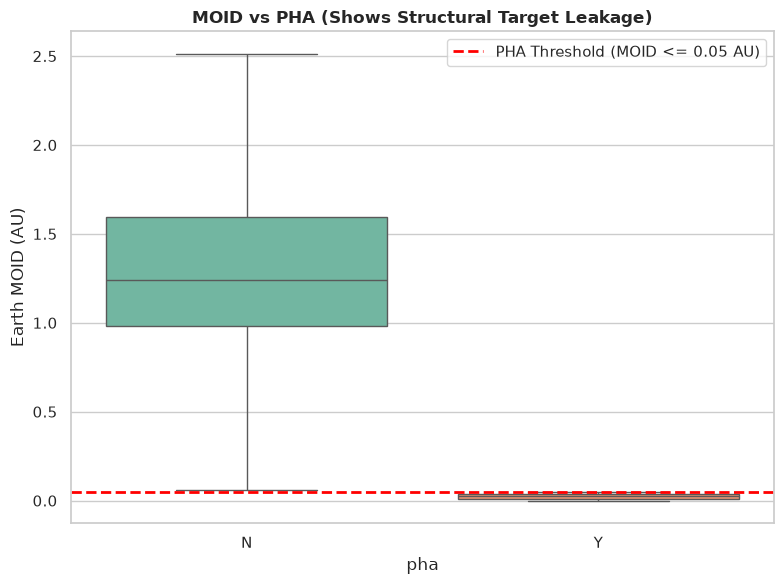

In [17]:
# Fallback to 'df' if columns were dropped in 'df_clean'
df_plot = df_clean.copy()

# PLOT 1: MOID vs PHA (Leakage Inspection)
# Use 'df' if 'moid' was excluded from 'df_clean'
source_df_1 = (
    df_plot if "moid" in df_plot.columns else df if "df" in locals() else None
)

plt.figure(figsize=(8, 6))

if (
    source_df_1 is not None
    and "moid" in source_df_1.columns
    and "pha" in source_df_1.columns
):

    # Ensure binary format for plotting
    plot_data = source_df_1.dropna(subset=["moid", "pha"]).copy()

    sns.boxplot(
        x="pha",
        y="moid",
        data=plot_data,
        palette="Set2",
        showfliers=False,
    )
    plt.axhline(
        0.05,
        color="red",
        linestyle="--",
        linewidth=2,
        label="PHA Threshold (MOID <= 0.05 AU)",
    )

    plt.title(
        "MOID vs PHA (Shows Structural Target Leakage)", fontweight="bold"
    )
    plt.ylabel("Earth MOID (AU)")
    plt.legend()
else:
    plt.text(
        0.5,
        0.5,
        "Column 'moid' or 'pha' not found\nin DataFrame",
        ha="center",
        va="center",
        fontsize=12,
    )

plt.tight_layout()
plt.show()

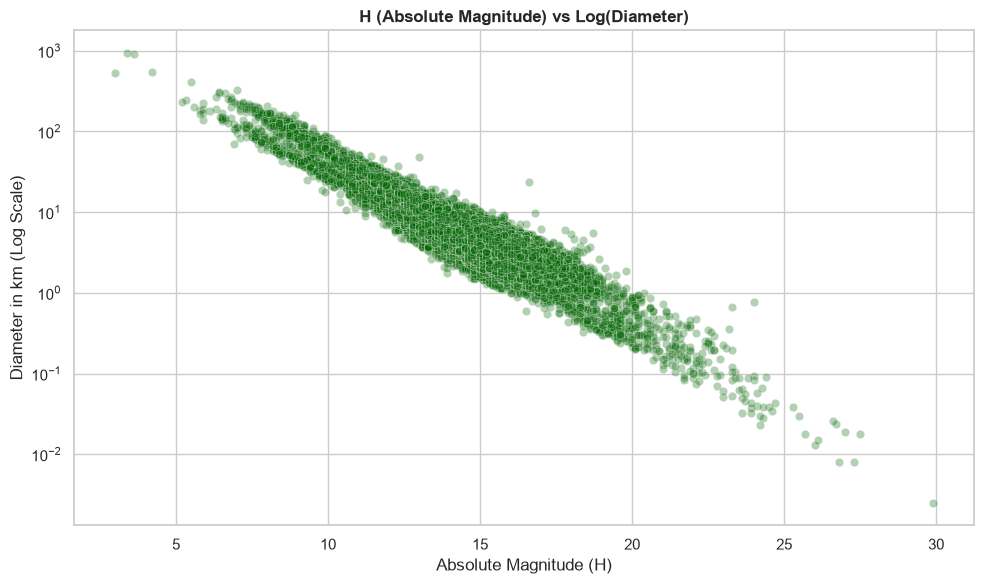

In [18]:
# Set style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

# ------------------------------------------------------------------------------
# PLOT 2: Absolute Magnitude H vs Diameter
# ------------------------------------------------------------------------------
df_plot2 = df.dropna(subset=["H", "diameter"]).copy()
df_plot2["diameter"] = pd.to_numeric(df_plot2["diameter"], errors="coerce")
df_plot2["H"] = pd.to_numeric(df_plot2["H"], errors="coerce")
df_plot2 = df_plot2.dropna(subset=["H", "diameter"])

sns.scatterplot(
    x="H", y="diameter", data=df_plot2, alpha=0.3, color="darkgreen"
)
plt.yscale("log")
plt.title("H (Absolute Magnitude) vs Log(Diameter)", fontweight="bold")
plt.xlabel("Absolute Magnitude (H)")
plt.ylabel("Diameter in km (Log Scale)")

plt.tight_layout()
plt.show()

# ==============================================================================
# 3. MULTICOLLINEARITY CORRELATION HEATMAP
# ==============================================================================

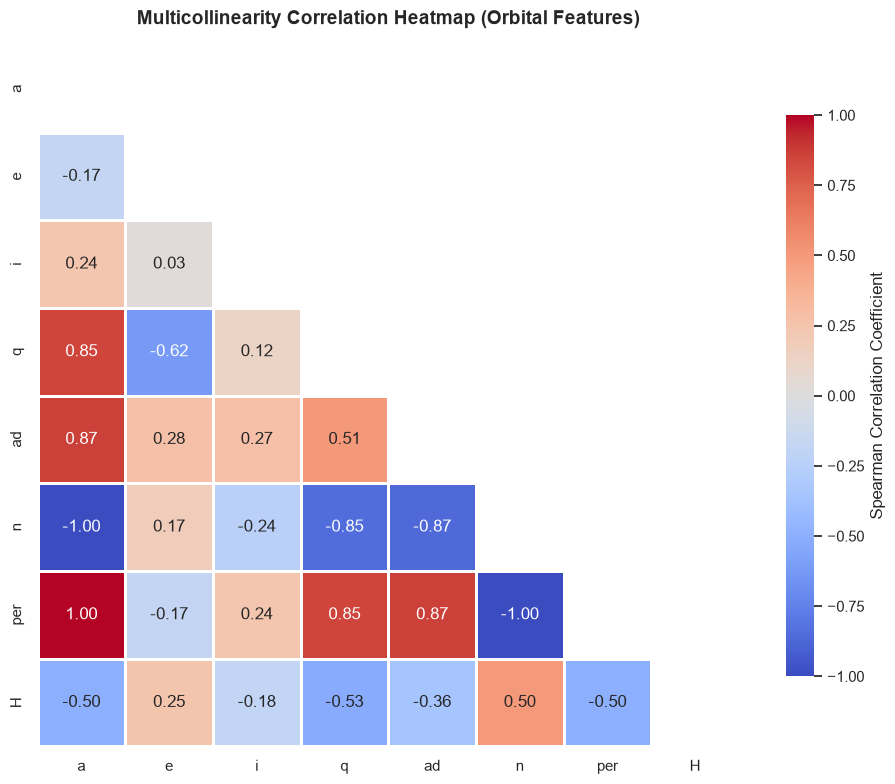

In [ ]:
import numpy as np


# Set visual style
sns.set_theme(style="white")

# 1. Select numeric orbital features present in your dataset
candidate_cols = ["a", "e", "i", "q", "ad", "n", "per", "H", "moid"]
# Fallback to df if df_clean is missing columns
source_df = (
    df_clean
    if all(c in df_clean.columns for c in candidate_cols[:3])
    else df)
num_cols = [c for c in candidate_cols if c in source_df.columns]

# Ensure data is numeric
heatmap_data = source_df[num_cols].apply(pd.to_numeric, errors="coerce").dropna()

# 2. Compute Spearman Correlation Matrix
corr = heatmap_data.corr(method="spearman")

# 3. Render Heatmap
plt.figure(figsize=(10, 8))

# Mask upper triangle to avoid redundant display
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1,
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Spearman Correlation Coefficient"},)

plt.title(
    "Multicollinearity Correlation Heatmap (Orbital Features)",
    fontsize=14,
    fontweight="bold",
    pad=15,)
plt.tight_layout()
plt.show()

Save cleaned dataset

In [53]:
df.to_csv("pha_dataset_cleaned.csv", index=False)